# Imports

In [71]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Data read

In [72]:
data_dir = Path()
csv_file_path = data_dir / "creditcard.csv"

In [73]:
credit_card_raw_data = pd.read_csv(csv_file_path)

credit_card_data = credit_card_raw_data.copy()



In [74]:
credit_card_data.head(5)

#Time -> represents the seconds elapsed between first transaction in the dataset
# V1 - V28 -> principal components obtained with PCA, the original features are not provided due to confidentiality issues
# Amount -> transaction amount
# Class -> target variable, 1 for fraud and 0 for non-fraud transactions

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


# Data Pre-processing

In [75]:
#1. data summary function

def data_summary(data_frame, max_examples=3, duplicates_delete=False):
    """Returns summary table of every column in data frame. Returns also selected number of examples for each column. 
    Default number of examples is 3. If duplicates_delete is True, duplicates are removed before summary calculation."""
    rows = []

    if duplicates_delete:
        data_frame = data_frame.drop_duplicates()

    for col in data_frame.columns:
        d = data_frame[col]
        record = {
            "column": col,
            "data_type": d.dtype,
            "not empty": d.notna().sum(),
            "missings": d.isna().sum(),
            "missings_%": d.isna().sum() / len(d) * 100,
            "unique": d.nunique(),
            "unique_%": d.nunique() / len(d) * 100,
            "examples": ", ".join(map(str, d.dropna().unique()[: max_examples])),
        }
        if pd.api.types.is_numeric_dtype(d):
            record["mean"] = d.mean()
            record["median"] = d.median()
            record["mode"] = d.mode().iloc[0] if not d.mode().empty else None
            record["std"] = d.std()
            record["min"] = d.min()
            record["max"] = d.max()

        rows.append(record)

    return pd.DataFrame(rows).set_index("column")

data_summary_df = data_summary(credit_card_data)

display(data_summary_df)

fraud_transactions_count = credit_card_data[credit_card_data["Class"] == 1].shape[0]
print("Fraud transactions count: ", fraud_transactions_count)


,data_type,not empty,missings,missings_%,unique,unique_%,examples,mean,median,mode,std,min,max
column,,,,,,,,,,,,,
Time,float64,284807,0,0.0,124592,43.746116,"0.0, 1.0, 2.0",9.481386e+04,84692.000000,163152.000000,47488.145955,0.000000,172792.000000
V1,float64,284807,0,0.0,275663,96.789405,"-1.3598071336738, 1.19185711131486, -1.3583540...",1.175161e-15,0.018109,1.245674,1.958696,-56.407510,2.454930
V2,float64,284807,0,0.0,275663,96.789405,"-0.0727811733098497, 0.26615071205963, -1.3401...",3.384974e-16,0.065486,-0.326668,1.651309,-72.715728,22.057729
V3,float64,284807,0,0.0,275663,96.789405,"2.53634673796914, 0.16648011335321, 1.77320934...",-1.379537e-15,0.179846,-2.752041,1.516255,-48.325589,9.382558
V4,float64,284807,0,0.0,275663,96.789405,"1.37815522427443, 0.448154078460911, 0.3797795...",2.094852e-15,-0.019847,-0.842316,1.415869,-5.683171,16.875344
V5,float64,284807,0,0.0,275663,96.789405,"-0.338320769942518, 0.0600176492822243, -0.503...",1.021879e-15,-0.054336,-0.562777,1.380247,-113.743307,34.801666
V6,float64,284807,0,0.0,275663,96.789405,"0.462387777762292, -0.0823608088155687, 1.8004...",1.494498e-15,-0.274187,-1.011073,1.332271,-26.160506,73.301626
V7,float64,284807,0,0.0,275663,96.789405,"0.239598554061257, -0.0788029833323113, 0.7914...",-5.620335e-16,0.040103,-0.432126,1.237094,-43.557242,120.589494
V8,float64,284807,0,0.0,275663,96.789405,"0.0986979012610507, 0.0851016549148104, 0.2476...",1.149614e-16,0.022358,-0.160211,1.194353,-73.216718,20.007208


Fraud transactions count:  492


In [76]:
#2. Data shape
print(f"Data shape: {credit_card_data.shape}")



Data shape: (284807, 31)


In [77]:
#3. Duplicates in all data

duplicates = credit_card_data.duplicated().sum()
print("Duplicates in data: ", duplicates)

#4. Duplicates in fraud transactions
duplicates_in_frauds = credit_card_data[credit_card_data["Class"] == 1].duplicated().sum()
print("Duplicates in fraud transactions: ", duplicates_in_frauds)

#5. Duplicates without "Class" column
duplicates_without_class = credit_card_data.drop(columns=["Class"])
duplicates_without_class_count = duplicates_without_class.duplicated().sum()
print("Duplicates without 'Class' column: ", duplicates_without_class_count)

duplicated_df = credit_card_data[credit_card_data.duplicated()]
display(duplicated_df)


Duplicates in data:  1081
Duplicates in fraud transactions:  19
Duplicates without 'Class' column:  1081


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
282987,171288.0,1.912550,-0.455240,-1.750654,0.454324,2.089130,4.160019,-0.881302,1.081750,1.022928,...,-0.524067,-1.337510,0.473943,0.616683,-0.283548,-1.084843,0.073133,-0.036020,11.99,0
283483,171627.0,-1.464380,1.368119,0.815992,-0.601282,-0.689115,-0.487154,-0.303778,0.884953,0.054065,...,0.287217,0.947825,-0.218773,0.082926,0.044127,0.639270,0.213565,0.119251,6.82,0
283485,171627.0,-1.457978,1.378203,0.811515,-0.603760,-0.711883,-0.471672,-0.282535,0.880654,0.052808,...,0.284205,0.949659,-0.216949,0.083250,0.044944,0.639933,0.219432,0.116772,11.93,0
284191,172233.0,-2.667936,3.160505,-3.355984,1.007845,-0.377397,-0.109730,-0.667233,2.309700,-1.639306,...,0.391483,0.266536,-0.079853,-0.096395,0.086719,-0.451128,-1.183743,-0.222200,55.66,0


In [78]:
#6. Summary table for duplicates for checking metrics

data_summary_duplicates_df = data_summary(duplicated_df)

In [79]:
#7. Summary table for all transactions without duplicates

data_summary_no_duplicates_df = data_summary(credit_card_data, duplicates_delete=True)
display(data_summary_no_duplicates_df)

,data_type,not empty,missings,missings_%,unique,unique_%,examples,mean,median,mode,std,min,max
column,,,,,,,,,,,,,
Time,float64,283726,0,0.0,124592,43.912789,"0.0, 1.0, 2.0",94811.077600,84692.500000,3767.000000,47481.047891,0.000000,172792.000000
V1,float64,283726,0,0.0,275663,97.158174,"-1.3598071336738, 1.19185711131486, -1.3583540...",0.005917,0.020384,1.245674,1.948026,-56.407510,2.454930
V2,float64,283726,0,0.0,275663,97.158174,"-0.0727811733098497, 0.26615071205963, -1.3401...",-0.004135,0.063949,-0.326668,1.646703,-72.715728,22.057729
V3,float64,283726,0,0.0,275663,97.158174,"2.53634673796914, 0.16648011335321, 1.77320934...",0.001613,0.179963,-2.752041,1.508682,-48.325589,9.382558
V4,float64,283726,0,0.0,275663,97.158174,"1.37815522427443, 0.448154078460911, 0.3797795...",-0.002966,-0.022248,-0.842316,1.414184,-5.683171,16.875344
V5,float64,283726,0,0.0,275663,97.158174,"-0.338320769942518, 0.0600176492822243, -0.503...",0.001828,-0.053468,-0.562777,1.377008,-113.743307,34.801666
V6,float64,283726,0,0.0,275663,97.158174,"0.462387777762292, -0.0823608088155687, 1.8004...",-0.001139,-0.275168,-1.011073,1.331931,-26.160506,73.301626
V7,float64,283726,0,0.0,275663,97.158174,"0.239598554061257, -0.0788029833323113, 0.7914...",0.001801,0.040859,-0.432126,1.227664,-43.557242,120.589494
V8,float64,283726,0,0.0,275663,97.158174,"0.0986979012610507, 0.0851016549148104, 0.2476...",-0.000854,0.021898,-0.160211,1.179054,-73.216718,20.007208


In [80]:
#8. Comparison of data summary function

def data_summary_comparison(all_data_df, no_duplicates_df):
    """something"""
    #trzeba zrobić tak, zrobic nowy dataframe ktory bedzie mial kolumny takie same jak orginalny co badamy, pobierac wartosci z orginalnych data_framow zeby obliczyc roznice, dodac kolumny z difem %

    record = {
        "mean_diff": round(no_duplicates_df["mean"] - all_data_df["mean"], 2),
        "mean_diff_%": round((no_duplicates_df["mean"] - all_data_df["mean"]) / all_data_df["mean"] * 100, 2),
        "median_diff": round(no_duplicates_df["median"] - all_data_df["median"], 2),
        "median_diff_%": round((no_duplicates_df["median"] - all_data_df["median"]) / all_data_df["median"] *100, 2),
        "mode_diff": round(no_duplicates_df["mode"] - all_data_df["mode"], 2),
        "mode_diff_%": round((no_duplicates_df["mode"] - all_data_df["mode"]) / all_data_df["mode"] * 100, 2),
        "std_diff": round(no_duplicates_df["std"] - all_data_df["std"], 2),
        "std_diff_%": round((no_duplicates_df["std"] - all_data_df["std"]) / all_data_df["std"] * 100, 2),
        "min_diff": round(no_duplicates_df["min"] - all_data_df["min"], 2),
        "min_diff_%": round((no_duplicates_df["min"] - all_data_df["min"]) / all_data_df["min"] * 100, 2),
        "max_diff": round(no_duplicates_df["max"] - all_data_df["max"], 2),
        "max_diff_%": round((no_duplicates_df["max"] - all_data_df["max"]) / all_data_df["max"] * 100, 2)
    }
            
    summary_df = pd.DataFrame(record, index=all_data_df.index)

    return summary_df


data_summary_comparison_beetween_data_summary_df_and_no_duplicates_df = data_summary_comparison(data_summary_df, data_summary_no_duplicates_df)
display(data_summary_comparison_beetween_data_summary_df_and_no_duplicates_df)


    
    

,mean_diff,mean_diff_%,median_diff,median_diff_%,mode_diff,mode_diff_%,std_diff,std_diff_%,min_diff,min_diff_%,max_diff,max_diff_%
column,,,,,,,,,,,,
Time,-2.78,-0.000000e+00,0.5,0.00,-159385.0,-97.69,-7.10,-0.01,0.0,NaN,0.0,0.0
V1,0.01,5.035183e+14,0.0,12.56,0.0,0.00,-0.01,-0.54,0.0,-0.0,0.0,0.0
V2,-0.00,-1.221503e+15,-0.0,-2.35,0.0,-0.00,-0.00,-0.28,0.0,-0.0,0.0,0.0
V3,0.00,-1.169320e+14,0.0,0.06,0.0,-0.00,-0.01,-0.50,0.0,-0.0,0.0,0.0
V4,-0.00,-1.415999e+14,-0.0,12.10,0.0,-0.00,-0.00,-0.12,0.0,-0.0,0.0,0.0
V5,0.00,1.788431e+14,0.0,-1.60,0.0,-0.00,-0.00,-0.23,0.0,-0.0,0.0,0.0
V6,-0.00,-7.624554e+13,-0.0,0.36,0.0,-0.00,-0.00,-0.03,0.0,-0.0,0.0,0.0
V7,0.00,-3.203887e+14,0.0,1.89,0.0,-0.00,-0.01,-0.76,0.0,-0.0,0.0,0.0
V8,-0.00,-7.432518e+14,-0.0,-2.06,0.0,-0.00,-0.02,-1.28,0.0,-0.0,0.0,0.0


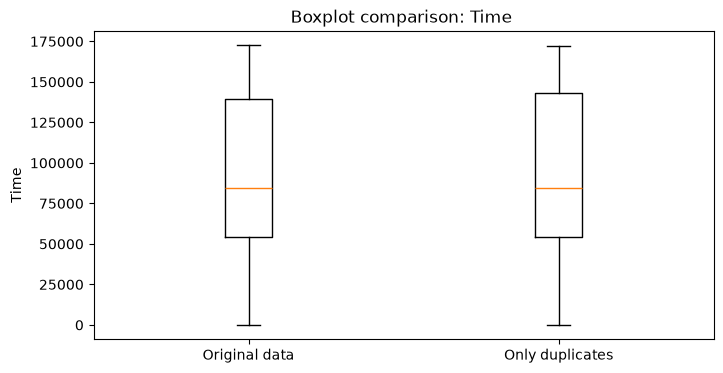

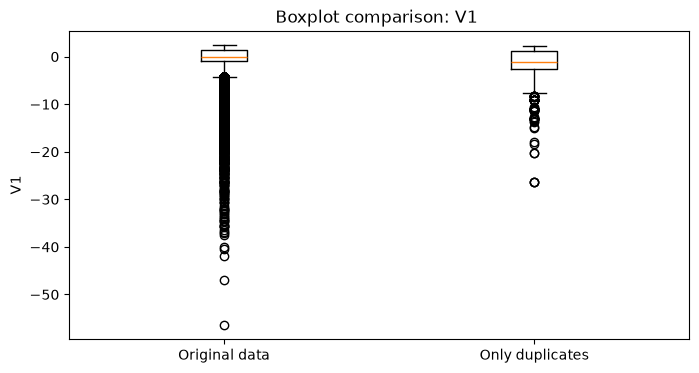

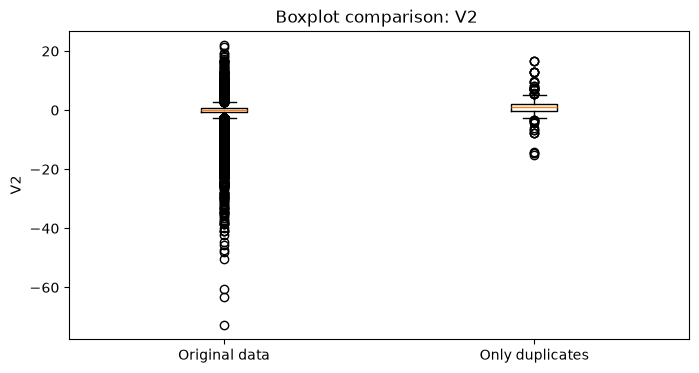

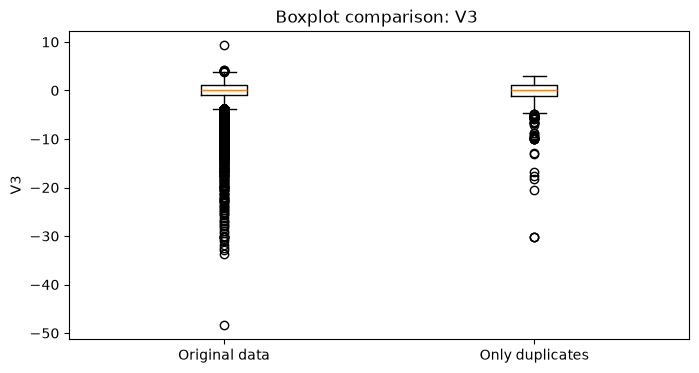

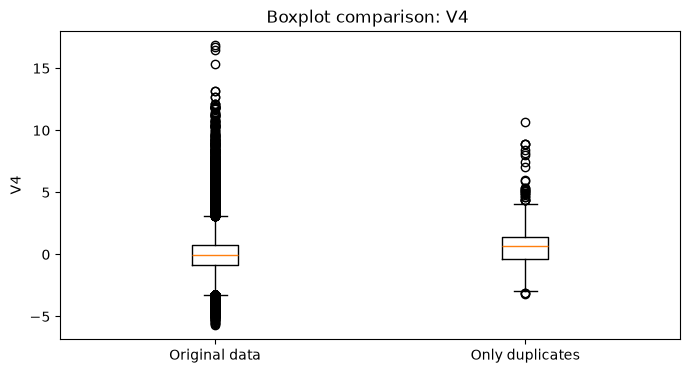

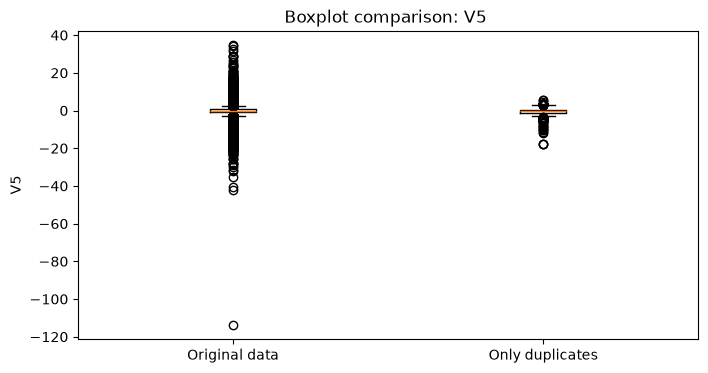

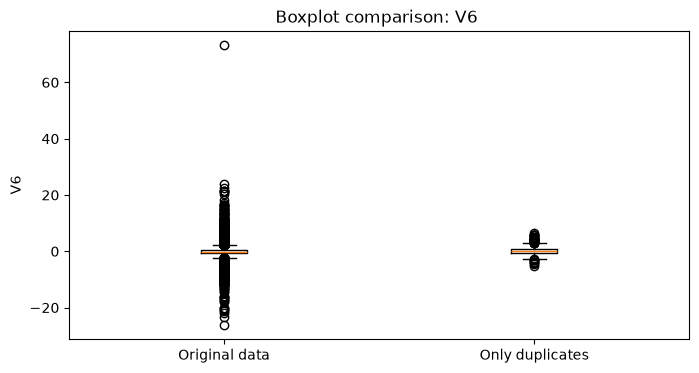

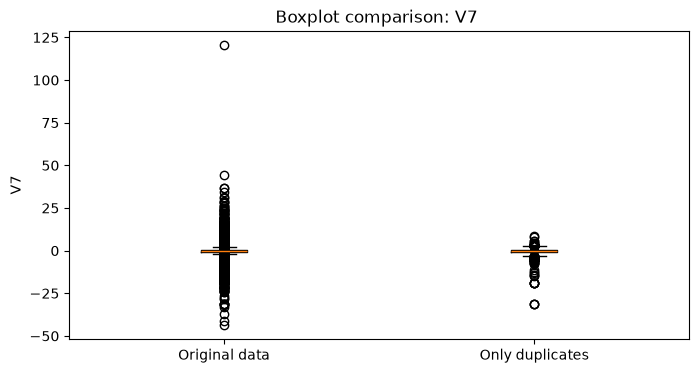

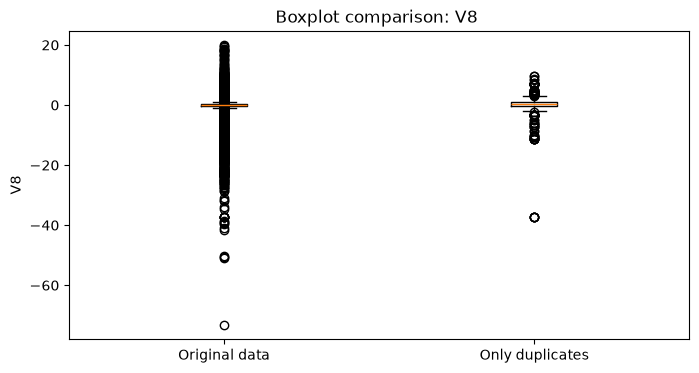

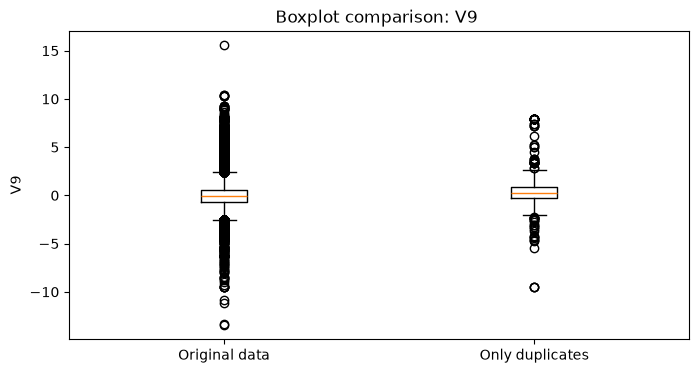

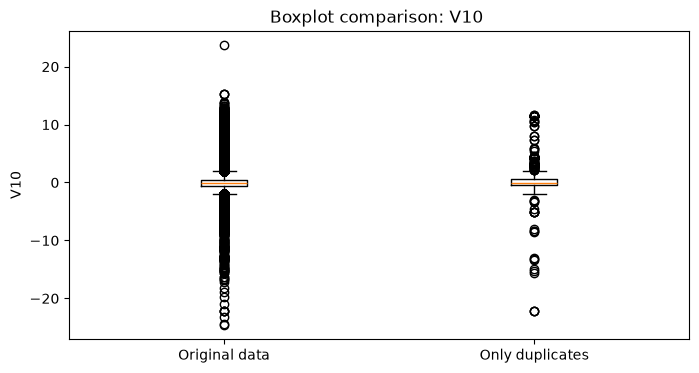

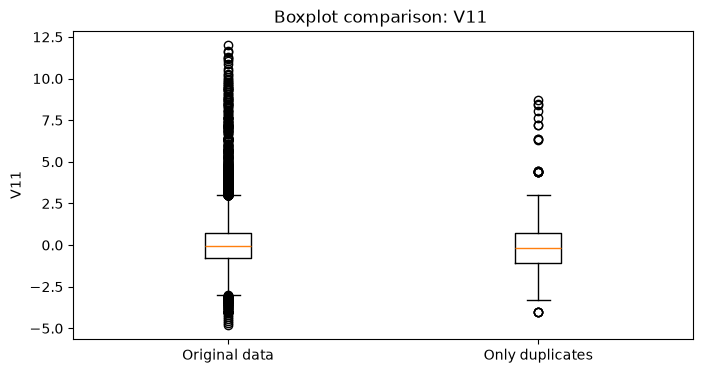

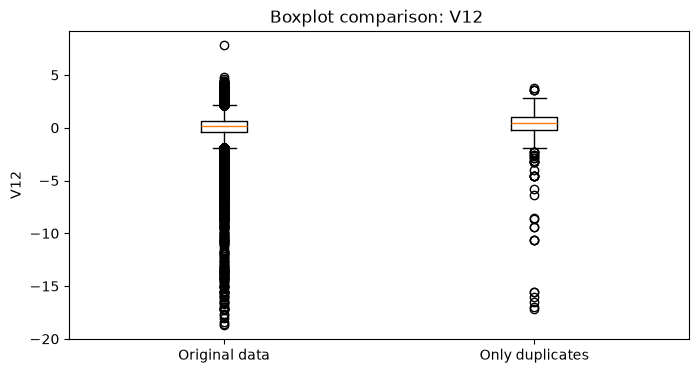

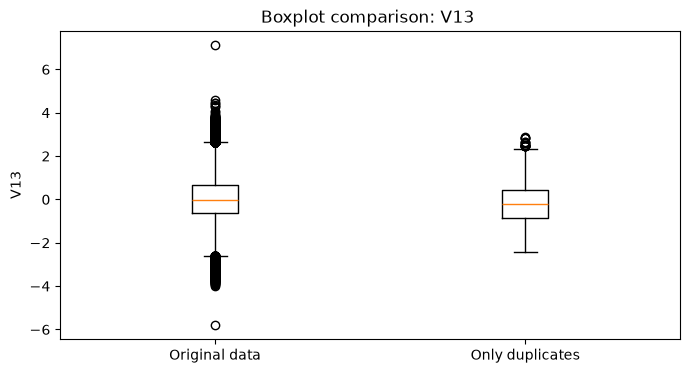

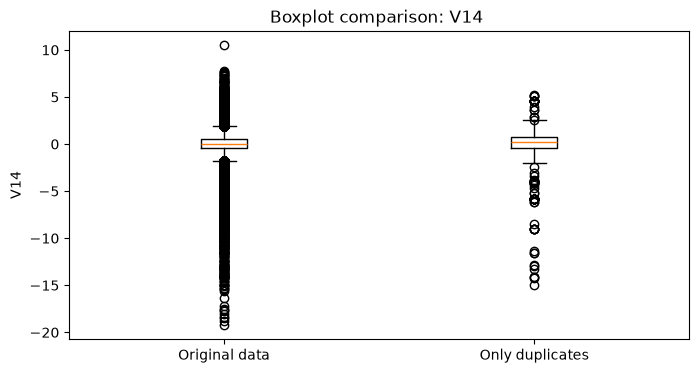

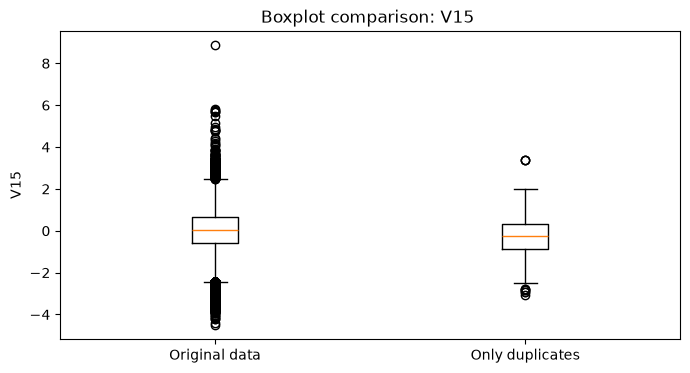

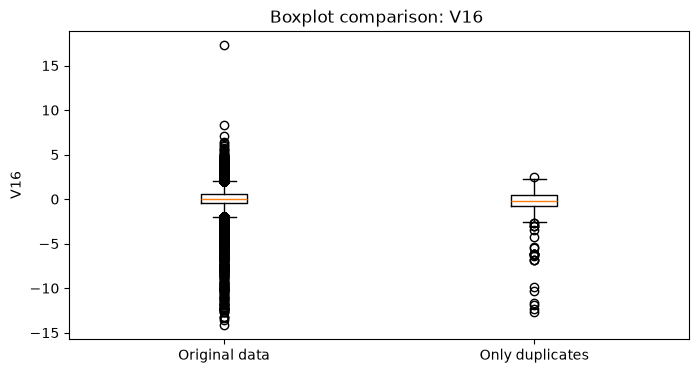

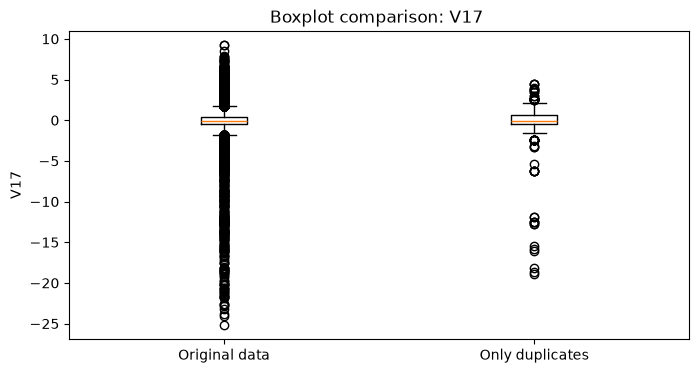

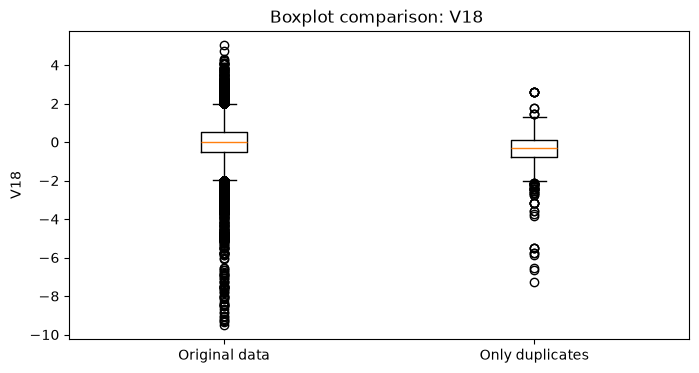

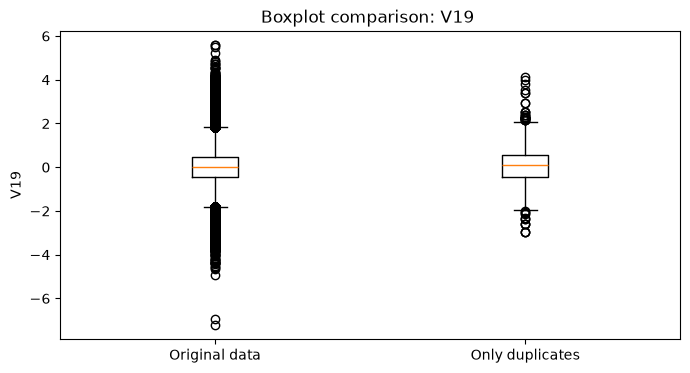

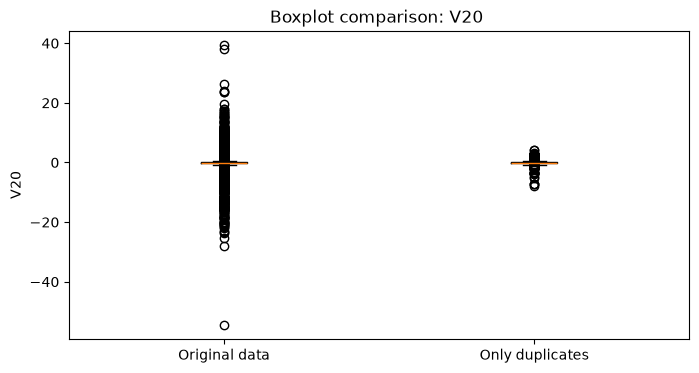

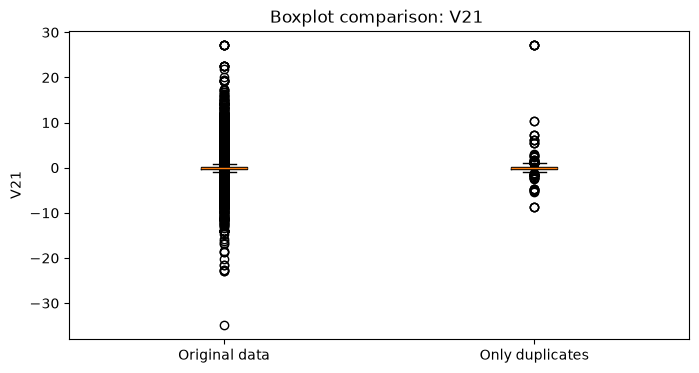

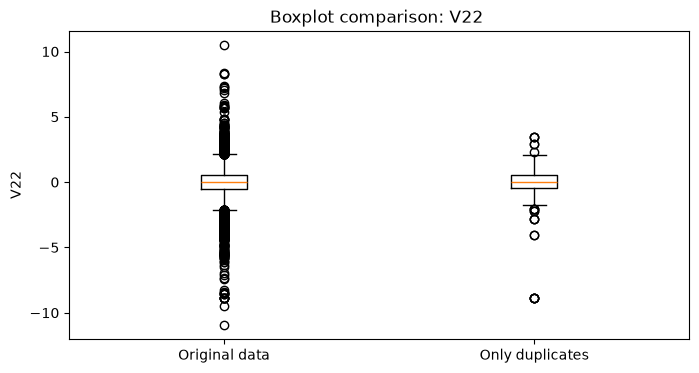

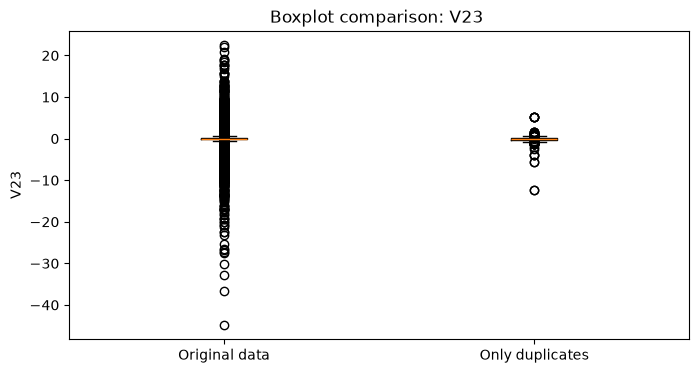

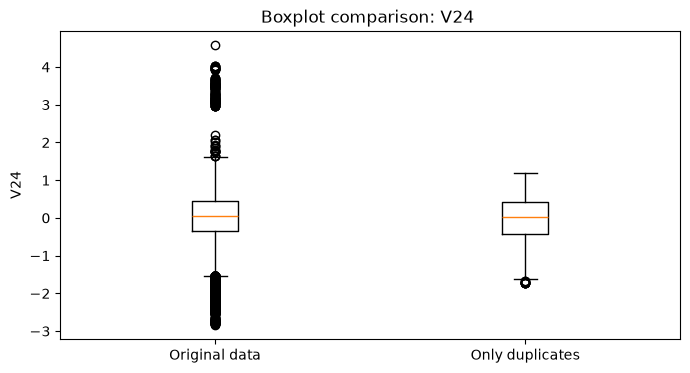

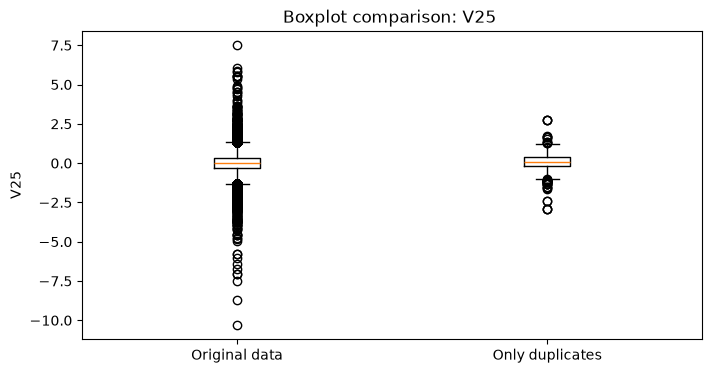

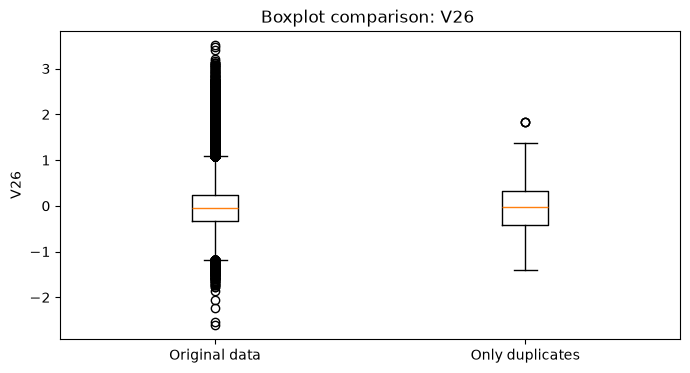

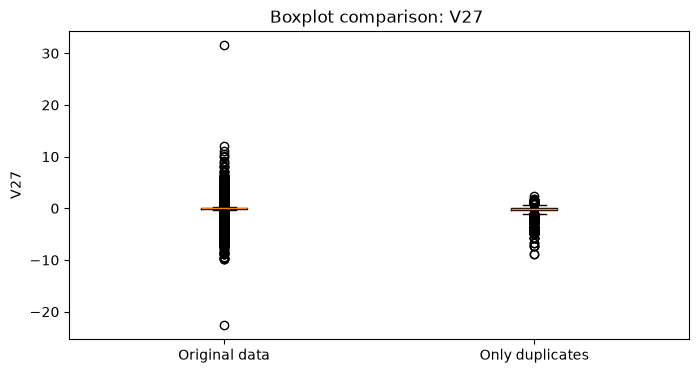

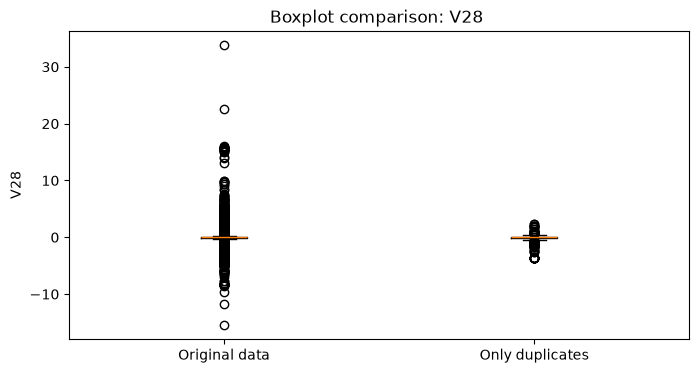

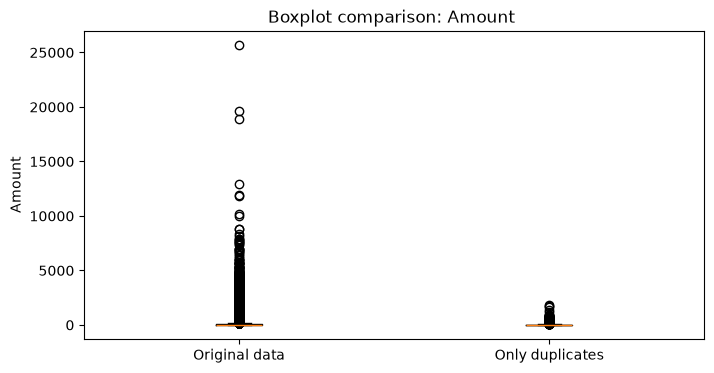

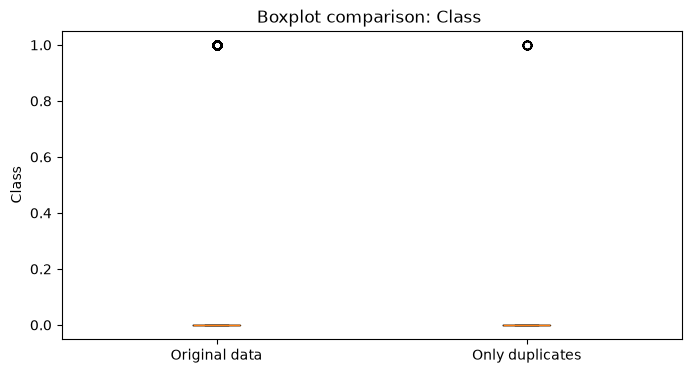

In [82]:
#9. Boxplot chart for all data and only duplicates
credit_card_data_only_duplicates = credit_card_data[credit_card_data.duplicated()]

for col in credit_card_data.columns:
    plt.figure(figsize=(8, 4))

    plt.boxplot(
        [
            credit_card_data[col],
            credit_card_data_only_duplicates[col]
        ],
        tick_labels=["Original data", "Only duplicates"]
    )

    plt.title(f"Boxplot comparison: {col} ")
    plt.ylabel(col)
    plt.show()

# Review
- dlaczego mamy duplikaty (powiniśmy odezwać się do dostarczyciela danych)
- sprawdzić duplikaty bez cechy "Class" żeby zobaczyć czy mam takie same cechy
- może być tak że rzeczywiście transakcje się powtarzały i wśroód nich były fraudy, może była tu częściowa augumentacja
- nie mając informacji szedłby w stronę powywalania duplikatów
- porównać rozkłady dla wszystkich zmiennych (podstawowe statystyki dla wszystkich zmiennych) pomiędzy duplikatami a nieduplikatami
- narysować szereg czasowy i poszukać jakiejś cyklicznośći we fraudach
- nie użyłby czasu do modelowania no bo jaka niby miałaby być relacja, że model się nauczy że im później to będzie więcej fraudów? xd
- decyzja czy zostawić duplikaty będzie wgl decyzją jak podejść do problemu bo wpłynie to na metryki, bo chyba fraudów mam więcej w duplikatach niż w nieduplikatach
- spróbowałby podzielić dane czasem, czyli 60% na trening, 20% valid i 20% test ale sprawdzić jak wygląda rozkład fraudów czy będzie podobny, jeśli nie to zamiast czasem użyć stratify aby mieć podobną ilość fraudów w każdym zbiorze, no bo co jeśli wykryje wzorzec na 60% transackji jak w pozostałych zbiorach nie będzie żadnego frauda xd


In [93]:
credit_card_data_only_duplicates[credit_card_data_only_duplicates["Time"] < 10]


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class


Dolny wąs: [5.3988e+04 2.6000e+01]
Górny wąs: [143083. 172233.]


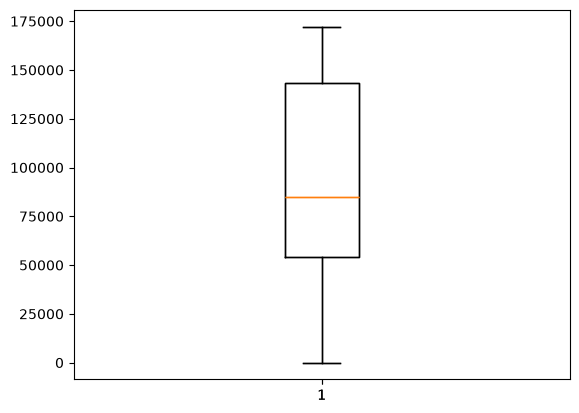

In [95]:
plt.boxplot(credit_card_data_only_duplicates["Time"])
result = plt.boxplot(credit_card_data_only_duplicates["Time"])

print("Dolny wąs:", result["whiskers"][0].get_ydata())
print("Górny wąs:", result["whiskers"][1].get_ydata())

plt.show()

In [92]:
q1 = credit_card_data_only_duplicates["Time"].quantile(0.25)
q3 = credit_card_data_only_duplicates["Time"].quantile(0.75)
iqr = q3 - q1

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Dolna granica:", q1 - 1.5 * iqr)

Q1: 53988.0
Q3: 143083.0
IQR: 89095.0
Dolna granica: -79654.5
